# Terraria Network Analysis

## Etapa 1 — construção do grafo de crafting

Usamos exclusivamente `items.json`, `recipes.json` e `milestones.json` de `data/raw/`.
O resultado é um `nx.DiGraph` chamado **`G`**: cada vértice é um item e cada aresta
**ingrediente → produto** indica uma dependência possível de crafting.

- A identidade dos vértices é `key`, usada pelas referências das receitas. O ID numérico,
  o nome e todos os demais atributos originais permanecem nos vértices.
- Receitas diferentes de um produto são alternativas. Dentro de uma receita, os slots
  de ingredientes são requisitos conjuntos; membros de um `group` são alternativas
  para aquele slot. Expandir o grupo não significa consumir todos os membros juntos.
- `recipes_desktop` preserva cada receita completa; as arestas guardam sua proveniência.
  O grafo sozinho não representa quantidades, condições e a lógica completa de crafting.
- Estações e condições são requisitos auxiliares, não arestas de ingrediente.
  `shimmer` é uma seção separada de transformações e fica fora desta etapa.
- Não calculamos centralidade, clustering ou redes sintéticas.

Execute todas as células em ordem no ambiente do projeto: `uv run jupyter notebook notebooks/analysis.ipynb`.
A busca dos dados funciona a partir da raiz do projeto ou de `notebooks/`.

In [1]:
import hashlib
import json
import sys
from collections import Counter, defaultdict
from copy import deepcopy
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data/raw/items.json").is_file()
     and (p / "notebooks/analysis.ipynb").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Execute a partir deste projeto; data/raw/items.json não foi encontrado.")
if Path(sys.prefix).resolve() != (PROJECT_ROOT / ".venv").resolve():
    raise RuntimeError("Selecione o kernel da .venv: uv run jupyter notebook notebooks/analysis.ipynb")

RAW_DIR = PROJECT_ROOT / "data/raw"
print(f"Python: {sys.version.split()[0]} | NetworkX: {nx.__version__}")
print(f"Ambiente: {sys.executable}")

Python: 3.12.13 | NetworkX: 3.7
Ambiente: /home/gengo/Workspace/Faculdade/Conteudos_de_estudo_6_semestre/Grafos/treinando_python_grafos/grafos_network/src/grafos_network/workspace_university/trabalho-3/.venv/bin/python


## 1. Leitura e inspeção da estrutura real

Primeiro exibimos tipos, campos e um exemplo, sem presumir que os três arquivos sejam listas.
Os hashes identificam os arquivos usados nesta execução. A validação seguinte interrompe
 o processamento se houver estrutura inesperada, quantidade inválida ou referência inexistente.

In [2]:
raw_data = {}
source_hashes = {}
for filename in ("items.json", "recipes.json", "milestones.json"):
    content = (RAW_DIR / filename).read_bytes()
    raw_data[filename] = json.loads(content)
    source_hashes[filename] = hashlib.sha256(content).hexdigest()

items_raw = raw_data["items.json"]
recipes_raw = raw_data["recipes.json"]
milestones_raw = raw_data["milestones.json"]

display(pd.DataFrame([
    {"arquivo": name, "tipo": type(value).__name__,
     "entradas_na_raiz": len(value) if isinstance(value, (list, dict)) else None,
     "sha256": source_hashes[name]}
    for name, value in raw_data.items()
]))
if isinstance(recipes_raw, dict):
    display(pd.DataFrame([
        {"seção": key, "tipo": type(value).__name__,
         "entradas": len(value) if isinstance(value, (list, dict)) else None}
        for key, value in recipes_raw.items()
    ]))
    records = recipes_raw.get("recipes", [])
    if isinstance(records, list) and all(isinstance(r, dict) for r in records):
        print("Campos das receitas (ocorrências):", dict(Counter(k for r in records for k in r)))
        print("Exemplo de receita:")
        print(json.dumps(records[0] if records else {}, indent=2, ensure_ascii=False))
for label, records in (("Itens", items_raw), ("Milestones", milestones_raw)):
    if isinstance(records, list) and records and isinstance(records[0], dict):
        print(f"{label}: campos do primeiro registro = {list(records[0])}")

,arquivo,tipo,entradas_na_raiz,sha256
0,items.json,list,6186,ee7318eb8c82142d95b12871766fe8471e715eda0ab33e...
1,recipes.json,dict,4,3623d67cbf4ddf3aa5ca97c1c609a7114f56632d156354...
2,milestones.json,list,16,495fb8c8722692782c0ffe765adc2fa702f0f09398fc8b...


,seção,tipo,entradas
0,stations,dict,42
1,groups,dict,34
2,recipes,list,3655
3,shimmer,list,287


Campos das receitas (ocorrências): {'result': 3655, 'amount': 3655, 'stations': 3655, 'ingredients': 3655, 'platforms': 319}
Exemplo de receita:
{
  "result": "MiniNukeI",
  "amount": 100,
  "stations": [
    "Autohammer"
  ],
  "ingredients": [
    {
      "item": "RocketIII",
      "amount": 100
    },
    {
      "item": "ShroomiteBar",
      "amount": 1
    }
  ]
}
Itens: campos do primeiro registro = ['key', 'id', 'name', 'internalName', 'page', 'url', 'icon', 'categories', 'subcategories', 'obtain', 'vendors', 'events', 'biomes', 'times', 'platforms', 'platformsKnown', 'introduced', 'version', 'hardmode', 'hardmodeOnly', 'unobtainable', 'banner', 'questFish', 'rarity', 'sell', 'research', 'stack', 'consumable', 'placeable', 'autoswing', 'damage', 'damageType', 'critical', 'knockback', 'useTime', 'pickaxePower', 'toolSpeed', 'conditions', 'milestone', 'milestoneVia']
Milestones: campos do primeiro registro = ['id', 'name', 'icon', 'count']


In [3]:
def require(condition, message):
    if not condition:
        raise ValueError(message)


def is_text(value):
    return isinstance(value, str) and bool(value.strip())


def is_string_list(value):
    return isinstance(value, list) and all(is_text(x) for x in value)


def is_quantity(value):
    return type(value) is int and value > 0


def validate_sources(items, crafting, milestones):
    """Valida os contratos observados sem preencher dados ausentes ou inventar IDs."""
    require(isinstance(items, list) and bool(items), "items.json deve conter uma lista não vazia.")
    require(isinstance(milestones, list), "milestones.json deve conter uma lista.")
    require(isinstance(crafting, dict), "recipes.json deve conter um objeto.")
    require(all(k in crafting for k in ("recipes", "groups", "stations", "shimmer")),
            "Faltam seções esperadas em recipes.json.")
    require(isinstance(crafting["recipes"], list), "recipes deve ser uma lista.")
    require(isinstance(crafting["shimmer"], list), "shimmer deve ser uma lista (fora do grafo).")

    milestone_index = {}
    for m in milestones:
        require(isinstance(m, dict), "Milestone deve ser objeto.")
        require(is_text(m.get("id")) and is_text(m.get("name")), "Milestone sem id/nome válido.")
        require(m["id"] not in milestone_index, f"Milestone duplicado: {m['id']}")
        require(type(m.get("count")) is int and m["count"] >= 0, "count de milestone inválido.")
        milestone_index[m["id"]] = m

    item_index = {}
    for item in items:
        require(isinstance(item, dict), "Item deve ser objeto.")
        require(is_text(item.get("key")) and is_text(item.get("name")), "Item sem key/nome válido.")
        key = item["key"]
        require(key not in item_index, f"key de item duplicada: {key}")
        require(type(item.get("id")) is int, f"ID inválido: {key}")
        require(is_string_list(item.get("platforms")), f"Plataformas inválidas: {key}")
        require(item.get("milestone") is None or item["milestone"] in milestone_index,
                f"Milestone desconhecido: {key}")
        item_index[key] = item

    for section in ("groups", "stations"):
        catalog = crafting[section]
        require(isinstance(catalog, dict), f"{section} deve ser um objeto.")
        for name, definition in catalog.items():
            require(is_text(name) and isinstance(definition, dict), f"Definição inválida em {section}.")
            members = definition.get("items", [])
            require(is_string_list(members), f"Membros inválidos: {name}")
            require(len(members) == len(set(members)), f"Membros duplicados: {name}")
            require(all(key in item_index for key in members), f"Item desconhecido em {section}: {name}")
            if section == "groups":
                require(bool(members), f"Grupo vazio: {name}")
            else:
                require(bool(members) or definition.get("condition") is True,
                        f"Estação sem itens ou condição: {name}")

    for index, recipe in enumerate(crafting["recipes"]):
        label = f"Receita [{index}]"
        require(isinstance(recipe, dict), f"{label}: deve ser objeto.")
        require(is_text(recipe.get("result")) and recipe["result"] in item_index,
                f"{label}: produto desconhecido.")
        require(is_quantity(recipe.get("amount")), f"{label}: quantidade do produto inválida.")
        require(is_string_list(recipe.get("stations")), f"{label}: estações inválidas.")
        require(all(s in crafting["stations"] for s in recipe["stations"]), f"{label}: estação desconhecida.")
        if "platforms" in recipe:
            require(is_string_list(recipe["platforms"]), f"{label}: plataformas inválidas.")
        ingredients = recipe.get("ingredients")
        require(isinstance(ingredients, list) and bool(ingredients), f"{label}: ingredientes vazios/inválidos.")
        for ingredient in ingredients:
            require(isinstance(ingredient, dict), f"{label}: ingrediente deve ser objeto.")
            selectors = set(ingredient) & {"item", "group"}
            require(len(selectors) == 1, f"{label}: use exatamente um seletor item ou group.")
            selector = next(iter(selectors))
            target = ingredient[selector]
            catalog = item_index if selector == "item" else crafting["groups"]
            require(is_text(target) and target in catalog, f"{label}: {selector} desconhecido: {target}")
            require(is_quantity(ingredient.get("amount")), f"{label}: quantidade do ingrediente inválida.")
    return item_index, milestone_index


items_by_key, milestones_by_id = validate_sources(items_raw, recipes_raw, milestones_raw)
recipe_groups = deepcopy(recipes_raw["groups"])
station_catalog = deepcopy(recipes_raw["stations"])

items_by_numeric_id = defaultdict(list)
for item in items_raw:
    items_by_numeric_id[item["id"]].append(item["key"])
id_collisions = {item_id: keys for item_id, keys in items_by_numeric_id.items() if len(keys) > 1}
display(pd.DataFrame([
    {"id_numérico_repetido": item_id, "keys_distintas": ", ".join(keys)}
    for item_id, keys in id_collisions.items()
]))
platform_counts = Counter(
    tuple(r["platforms"]) if "platforms" in r else ("sem restrição explícita",)
    for r in recipes_raw["recipes"]
)
display(pd.DataFrame([
    {"platforms": ", ".join(platforms), "receitas": count}
    for platforms, count in platform_counts.items()
]))
print("Esquemas de ingredientes:", dict(Counter(
    tuple(sorted(i)) for r in recipes_raw["recipes"] for i in r["ingredients"]
)))
print(f"Validação estrutural e referências: OK. IDs numéricos repetidos: {len(id_collisions)}.")
print(f"Itens sem milestone informado: {sum(i.get('milestone') is None for i in items_raw)}.")

,id_numérico_repetido,keys_distintas
0,5036,"OcramTrophy, MusicBoxOWMoonLord"
1,5048,"ShinyBlackSlab, RoninHat"
2,5052,"RainbowPiece, TimelessTravelerRobe"
3,5054,"FloretProtectorHelmet, MysteriousPackage"
4,5055,"FloretProtectorChestplate, GoldenSeaweed"
5,5076,"RedEnvelope, RoyalScepter"
6,5077,"GlassSlipper, MythicalRobe"
7,5078,"MythicalLionMask, PrinceUniform"
8,5079,"FirecrackerMobile, PrincePants"


,platforms,receitas
0,sem restrição explícita,3336
1,"desktop, console, mobile",309
2,"desktop, console, oldgen, mobile",7
3,"desktop, console, mobile, 3ds",3


Esquemas de ingredientes: {('amount', 'item'): 5756, ('amount', 'group'): 334}
Validação estrutural e referências: OK. IDs numéricos repetidos: 9.
Itens sem milestone informado: 50.


## 2. Critérios de processamento

**Inconsistência observada:** nove IDs numéricos identificam mais de uma `key` no catálogo.
Não corrigimos esses IDs por suposição nem fundimos itens diferentes: usamos `key` como
identidade e conservamos os dados originais. Nomes também podem se repetir.
Há 50 itens sem milestone; essa ausência é mantida, sem atribuir progressão artificialmente.

**Plataforma:** 319 receitas declaram `platforms` e todas incluem `desktop`;
3.336 omitem esse campo. Adotamos explicitamente a interpretação de que ausência significa
**sem restrição de plataforma informada**, e incluímos essas receitas se seus itens forem
compatíveis com desktop. Essa é uma política de leitura deste dataset, não uma comprovação
externa da disponibilidade de cada receita. O campo original permanece intacto.
Receitas com restrição explícita que exclua desktop são descartadas; opções de grupos são
filtradas pelas plataformas dos itens. Produto incompatível ou slot sem opção desktop
exclui a receita inteira, com motivo registrado.

**Alternativas e estações:** cada slot conserva `item` ou `group`, a quantidade e sua lista
resolvida de opções. Não geramos combinações cartesianas de grupos. Receitas distintas do
mesmo produto são preservadas separadamente. `stations` é mantido literalmente, incluindo
condições como `By Hand`, `Ecto Mist` e `Demon Altar`; os itens equivalentes de cada estação
ficam disponíveis no catálogo auxiliar. Não transformamos estações em ingredientes.

In [4]:
PLATFORM = "desktop"


def supports_platform(item_key, platform=PLATFORM):
    return platform in items_by_key[item_key]["platforms"]


def select_recipes(platform=PLATFORM):
    """Preserva as receitas originais e acrescenta resolução e proveniência locais."""
    selected = {}
    excluded = []
    filtered_options = []
    for source_index, recipe in enumerate(recipes_raw["recipes"]):
        reason = None
        if "platforms" in recipe and platform not in recipe["platforms"]:
            reason = "restrição explícita de plataforma"
        elif not supports_platform(recipe["result"], platform):
            reason = "produto incompatível com a plataforma"
        if reason:
            excluded.append({"source_index": source_index, "result": recipe["result"], "reason": reason})
            continue

        resolved = []
        for slot, ingredient in enumerate(recipe["ingredients"]):
            candidates = ([ingredient["item"]] if "item" in ingredient
                          else recipe_groups[ingredient["group"]]["items"])
            options = [key for key in candidates if supports_platform(key, platform)]
            for key in candidates:
                if key not in options:
                    filtered_options.append({"source_index": source_index, "slot": slot, "item": key})
            resolved.append({**deepcopy(ingredient), "options": options})
        if any(not slot["options"] for slot in resolved):
            excluded.append({"source_index": source_index, "result": recipe["result"],
                             "reason": "ingrediente sem opção compatível com a plataforma"})
            continue

        # ID local = posição no JSON (base zero); não é um ID oficial do jogo.
        selected[source_index] = {
            **deepcopy(recipe),
            "recipe_id": source_index,
            "source_index": source_index,
            "selected_platform": platform,
            "platform_basis": "explicit" if "platforms" in recipe else "unspecified",
            "resolved_ingredients": resolved,
            "station_requirements": [
                {"name": station, "definition": deepcopy(station_catalog[station])}
                for station in recipe["stations"]
            ],
        }
    return selected, excluded, filtered_options


recipes_desktop, excluded_recipes, filtered_group_options = select_recipes()
print(f"Receitas no arquivo: {len(recipes_raw['recipes'])}")
print(f"Receitas desktop processadas: {len(recipes_desktop)}")
print(f"Receitas excluídas: {len(excluded_recipes)}; opções filtradas: {len(filtered_group_options)}")
print(f"Receitas com grupos alternativos: {sum(any('group' in i for i in r['ingredients']) for r in recipes_desktop.values())}")
print(f"Transformações shimmer fora do escopo: {len(recipes_raw['shimmer'])}")
if excluded_recipes:
    display(pd.DataFrame(excluded_recipes))

Receitas no arquivo: 3655
Receitas desktop processadas: 3655
Receitas excluídas: 0; opções filtradas: 0
Receitas com grupos alternativos: 305
Transformações shimmer fora do escopo: 287


## 3. Construção do `DiGraph`

Adicionamos somente itens que aparecem como ingrediente ou produto de uma receita selecionada.
O par `(ingrediente, produto)` aparece uma única vez no `DiGraph`, mesmo que participe de
várias receitas. O atributo `uses` guarda cada ocorrência, com ID local da receita, slot,
quantidade e grupo de origem; `recipe_ids` permite consultar as receitas completas.
Não somamos quantidades de receitas alternativas nem criamos pesos artificiais.

In [5]:
G = nx.DiGraph(
    name="Terraria — dependências de crafting desktop",
    platform=PLATFORM,
    edge_direction="ingredient -> result",
    node_identity="key",
    source_hashes=deepcopy(source_hashes),
    missing_recipe_platforms="unrestricted_if_items_support_desktop",
)

for recipe_id, recipe in recipes_desktop.items():
    product = recipe["result"]
    for slot_index, ingredient in enumerate(recipe["resolved_ingredients"]):
        for ingredient_key in ingredient["options"]:
            for key in (ingredient_key, product):
                if key not in G:
                    attributes = deepcopy(items_by_key[key])
                    if attributes.get("milestone") is not None:
                        attributes["milestone_info"] = deepcopy(milestones_by_id[attributes["milestone"]])
                    G.add_node(key, **attributes)
            if not G.has_edge(ingredient_key, product):
                G.add_edge(ingredient_key, product, recipe_ids=[], uses=[])
            edge = G[ingredient_key][product]
            if recipe_id not in edge["recipe_ids"]:
                edge["recipe_ids"].append(recipe_id)
            edge["uses"].append({
                "recipe_id": recipe_id,
                "ingredient_index": slot_index,
                "amount": ingredient["amount"],
                "group": ingredient.get("group"),
            })

print(f"Grafo construído: {G.number_of_nodes():,} vértices e {G.number_of_edges():,} arestas.")

Grafo construído: 3,773 vértices e 7,045 arestas.


## 4. Validação executável

Além de conferir referências, verificamos a correspondência exata entre receitas e arestas,
a preservação dos atributos e dos requisitos, a ausência de isolados e o mínimo de 300 vértices.
Os casos reais `Any Iron Bar → Lesion Chest` e as duas receitas de `Night's Edge` verificam
que grupos e receitas alternativas não foram perdidos. Casos negativos derivados dos próprios
registros confirmam que referências inexistentes e quantidades inválidas são rejeitadas.

In [6]:
expected_edges = set()
expected_uses = set()
participating_items = set()
for recipe_id, recipe in recipes_desktop.items():
    original = recipes_raw["recipes"][recipe["source_index"]]
    assert all(recipe[field] == value for field, value in original.items())
    assert "platforms" not in original or PLATFORM in original["platforms"]
    assert supports_platform(recipe["result"])
    assert recipe["station_requirements"] == [
        {"name": s, "definition": station_catalog[s]} for s in original["stations"]
    ]
    participating_items.add(recipe["result"])
    assert len(recipe["resolved_ingredients"]) == len(original["ingredients"])
    for slot_index, (raw_slot, resolved_slot) in enumerate(zip(
        original["ingredients"], recipe["resolved_ingredients"], strict=True
    )):
        raw_options = ([raw_slot["item"]] if "item" in raw_slot
                       else recipes_raw["groups"][raw_slot["group"]]["items"])
        expected_options = [key for key in raw_options if supports_platform(key)]
        assert resolved_slot["options"] == expected_options and expected_options
        assert all(resolved_slot[field] == value for field, value in raw_slot.items())
        for key in expected_options:
            participating_items.add(key)
            expected_edges.add((key, original["result"]))
            expected_uses.add((key, original["result"], recipe_id, slot_index,
                               raw_slot["amount"], raw_slot.get("group")))

assert isinstance(G, nx.DiGraph) and not G.is_multigraph()
assert set(G) == participating_items
assert set(G.edges) == expected_edges
assert all(u in items_by_key and v in items_by_key for u, v in G.edges)
assert all(supports_platform(key) for key in G)
assert not list(nx.isolates(G))
assert G.number_of_nodes() >= 300
assert len(recipes_desktop) + len(excluded_recipes) == len(recipes_raw["recipes"])
for key, attributes in G.nodes(data=True):
    assert attributes["key"] == key
    assert all(attributes[field] == value for field, value in items_by_key[key].items())

actual_uses = []
for ingredient, product, attributes in G.edges(data=True):
    assert set(attributes["recipe_ids"]) == {u["recipe_id"] for u in attributes["uses"]}
    assert len(attributes["recipe_ids"]) == len(set(attributes["recipe_ids"]))
    for use in attributes["uses"]:
        actual_uses.append((ingredient, product, use["recipe_id"], use["ingredient_index"],
                            use["amount"], use["group"]))
assert len(actual_uses) == len(set(actual_uses))
assert set(actual_uses) == expected_uses

# Regressões baseadas em receitas reais: alternativas de grupo e de receita.
for alternative in ("IronBar", "LeadBar"):
    assert G.has_edge(alternative, "LesionChest")
    assert any(u["group"] == "Any Iron Bar" and u["amount"] == 2
               for u in G[alternative]["LesionChest"]["uses"])
night_recipes = [r for r in recipes_desktop.values() if r["result"] == "NightsEdge"]
assert len(night_recipes) == 2
assert any(any(i.get("item") == "LightsBane" for i in r["ingredients"]) for r in night_recipes)
assert any(any(i.get("item") == "BloodButcherer" for i in r["ingredients"]) for r in night_recipes)
assert set(G["BladeofGrass"]["NightsEdge"]["recipe_ids"]) == {r["recipe_id"] for r in night_recipes}

# Entradas inválidas devem falhar explicitamente, antes de construir o grafo.
for invalid_case in ("produto inexistente", "quantidade zero", "grupo inexistente"):
    changed = deepcopy(recipes_raw["recipes"][0])
    if invalid_case == "produto inexistente":
        changed["result"] = "__invalid_item__"
    elif invalid_case == "quantidade zero":
        changed["ingredients"][0]["amount"] = 0
    else:
        changed["ingredients"][0] = {"group": "__invalid_group__", "amount": 1}
    try:
        validate_sources(items_raw, {**recipes_raw, "recipes": [changed]}, milestones_raw)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Validação não rejeitou: {invalid_case}")

print("PASSOU: estrutura, referências, desktop, atributos e receitas completas.")
print("PASSOU: equivalência receitas/arestas, proveniência, grupos e receitas alternativas.")
print("PASSOU: nenhum isolado e pelo menos 300 vértices.")
print("PASSOU: 3 casos negativos rejeitados (produto, quantidade e grupo inválidos).")

PASSOU: estrutura, referências, desktop, atributos e receitas completas.
PASSOU: equivalência receitas/arestas, proveniência, grupos e receitas alternativas.
PASSOU: nenhum isolado e pelo menos 300 vértices.
PASSOU: 3 casos negativos rejeitados (produto, quantidade e grupo inválidos).


In [7]:
summary = {
    "Vértices": G.number_of_nodes(),
    "Arestas": G.number_of_edges(),
    "Receitas processadas": len(recipes_desktop),
    "Componentes fracamente conexas": nx.number_weakly_connected_components(G),
    "Componentes fortemente conexas": nx.number_strongly_connected_components(G),
    "Itens isolados": nx.number_of_isolates(G),
    "Arestas com referência inválida": sum(u not in items_by_key or v not in items_by_key for u, v in G.edges),
    "Autolaços observados": nx.number_of_selfloops(G),
}
display(pd.DataFrame(summary.items(), columns=["Verificação", "Resultado"]).set_index("Verificação"))
print("Todas as verificações passaram.")

,Resultado
Verificação,
Vértices,3773
Arestas,7045
Receitas processadas,3655
Componentes fracamente conexas,62
Componentes fortemente conexas,3423
Itens isolados,0
Arestas com referência inválida,0
Autolaços observados,0


Todas as verificações passaram.


## 5. Cinco conexões reais e consulta das receitas completas

Os exemplos abaixo são consultados em `G` e conferidos nas receitas de origem.
A quantidade exibida pertence à receita indicada; não é um peso da aresta.

In [8]:
example_pairs = [
    ("IronBar", "LesionChest"),
    ("LeadBar", "LesionChest"),
    ("NightsEdge", "TrueNightsEdge"),
    ("TrueExcalibur", "TerraBlade"),
    ("TrueNightsEdge", "TerraBlade"),
]
examples = []
for ingredient, product in example_pairs:
    assert G.has_edge(ingredient, product)
    use = G[ingredient][product]["uses"][0]
    recipe = recipes_desktop[use["recipe_id"]]
    examples.append({
        "ingrediente": G.nodes[ingredient]["name"],
        "key_ingrediente": ingredient,
        "produto": G.nodes[product]["name"],
        "key_produto": product,
        "quantidade_ingrediente": use["amount"],
        "quantidade_produto": recipe["amount"],
        "grupo_alternativo": use["group"],
        "estações/condições": ", ".join(recipe["stations"]),
        "receita (índice JSON)": use["recipe_id"],
    })
display(pd.DataFrame(examples))

terra_recipes = [r for r in recipes_desktop.values() if r["result"] == "TerraBlade"]
assert terra_recipes, "Não há receita desktop de Terra Blade nos dados."
print("Receita completa de Terra Blade, com resolução dos ingredientes e estações:")
print(json.dumps(terra_recipes[0], indent=2, ensure_ascii=False))

,ingrediente,key_ingrediente,produto,key_produto,quantidade_ingrediente,quantidade_produto,grupo_alternativo,estações/condições,receita (índice JSON)
0,Iron Bar,IronBar,Lesion Chest,LesionChest,2,1,Any Iron Bar,Decay Chamber,7
1,Lead Bar,LeadBar,Lesion Chest,LesionChest,2,1,Any Iron Bar,Decay Chamber,7
2,Night's Edge,NightsEdge,True Night's Edge,TrueNightsEdge,1,1,NaN,Mythril Anvil,3175
3,True Excalibur,TrueExcalibur,Terra Blade,TerraBlade,1,1,NaN,Mythril Anvil,3177
4,True Night's Edge,TrueNightsEdge,Terra Blade,TerraBlade,1,1,NaN,Mythril Anvil,3177


Receita completa de Terra Blade, com resolução dos ingredientes e estações:
{
  "result": "TerraBlade",
  "amount": 1,
  "stations": [
    "Mythril Anvil"
  ],
  "ingredients": [
    {
      "item": "BrokenHeroSword",
      "amount": 1
    },
    {
      "item": "TrueExcalibur",
      "amount": 1
    },
    {
      "item": "TrueNightsEdge",
      "amount": 1
    }
  ],
  "recipe_id": 3177,
  "source_index": 3177,
  "selected_platform": "desktop",
  "platform_basis": "unspecified",
  "resolved_ingredients": [
    {
      "item": "BrokenHeroSword",
      "amount": 1,
      "options": [
        "BrokenHeroSword"
      ]
    },
    {
      "item": "TrueExcalibur",
      "amount": 1,
      "options": [
        "TrueExcalibur"
      ]
    },
    {
      "item": "TrueNightsEdge",
      "amount": 1,
      "options": [
        "TrueNightsEdge"
      ]
    }
  ],
  "station_requirements": [
    {
      "name": "Mythril Anvil",
      "definition": {
        "items": [
          "MythrilAnvil",
  

## 6. Cadeia completa de dependências da Terra Blade

Incluímos **todos os ancestrais da Terra Blade em `G`**, sem limitar a profundidade:
minérios → barras → espadas intermediárias → Terra Blade, além dos demais ingredientes.
A expansão termina nos itens sem receita anterior ou em itens já visitados. Assim, os ciclos
reais de conversão e reciclagem não causam expansão infinita.

- Cada coluna indica a distância mínima de crafting até a Terra Blade; as setas seguem
  **ingrediente → produto**. Não se trata de uma ordem obrigatória de execução.
- Setas azuis tracejadas indicam opções de receita/grupo. Por exemplo, **Light's Bane ou
  Blood Butcherer** podem compor Night's Edge; as duas espadas não são exigidas juntas.
- Setas laranja curvas indicam conversões reversíveis presentes nas receitas, incluindo
  trocas de minérios/barras e reciclagem de paredes. Todas permanecem no recorte.
- Os números das setas são quantidades do ingrediente **por receita**, sem acumular o
  custo total. A tabela preserva receitas alternativas, rendimento e estações/condições.
- Itens sem receita anterior no dataset encerram a cadeia de crafting; isso não significa
  que todos sejam minerados. Não inventamos receitas para itens obtidos por outros meios.

Este é o subgrafo completo de dependências da Terra Blade **nos JSONs fornecidos**, não
um roteiro único de fabricação nem uma árvore que elimina conversões cíclicas.

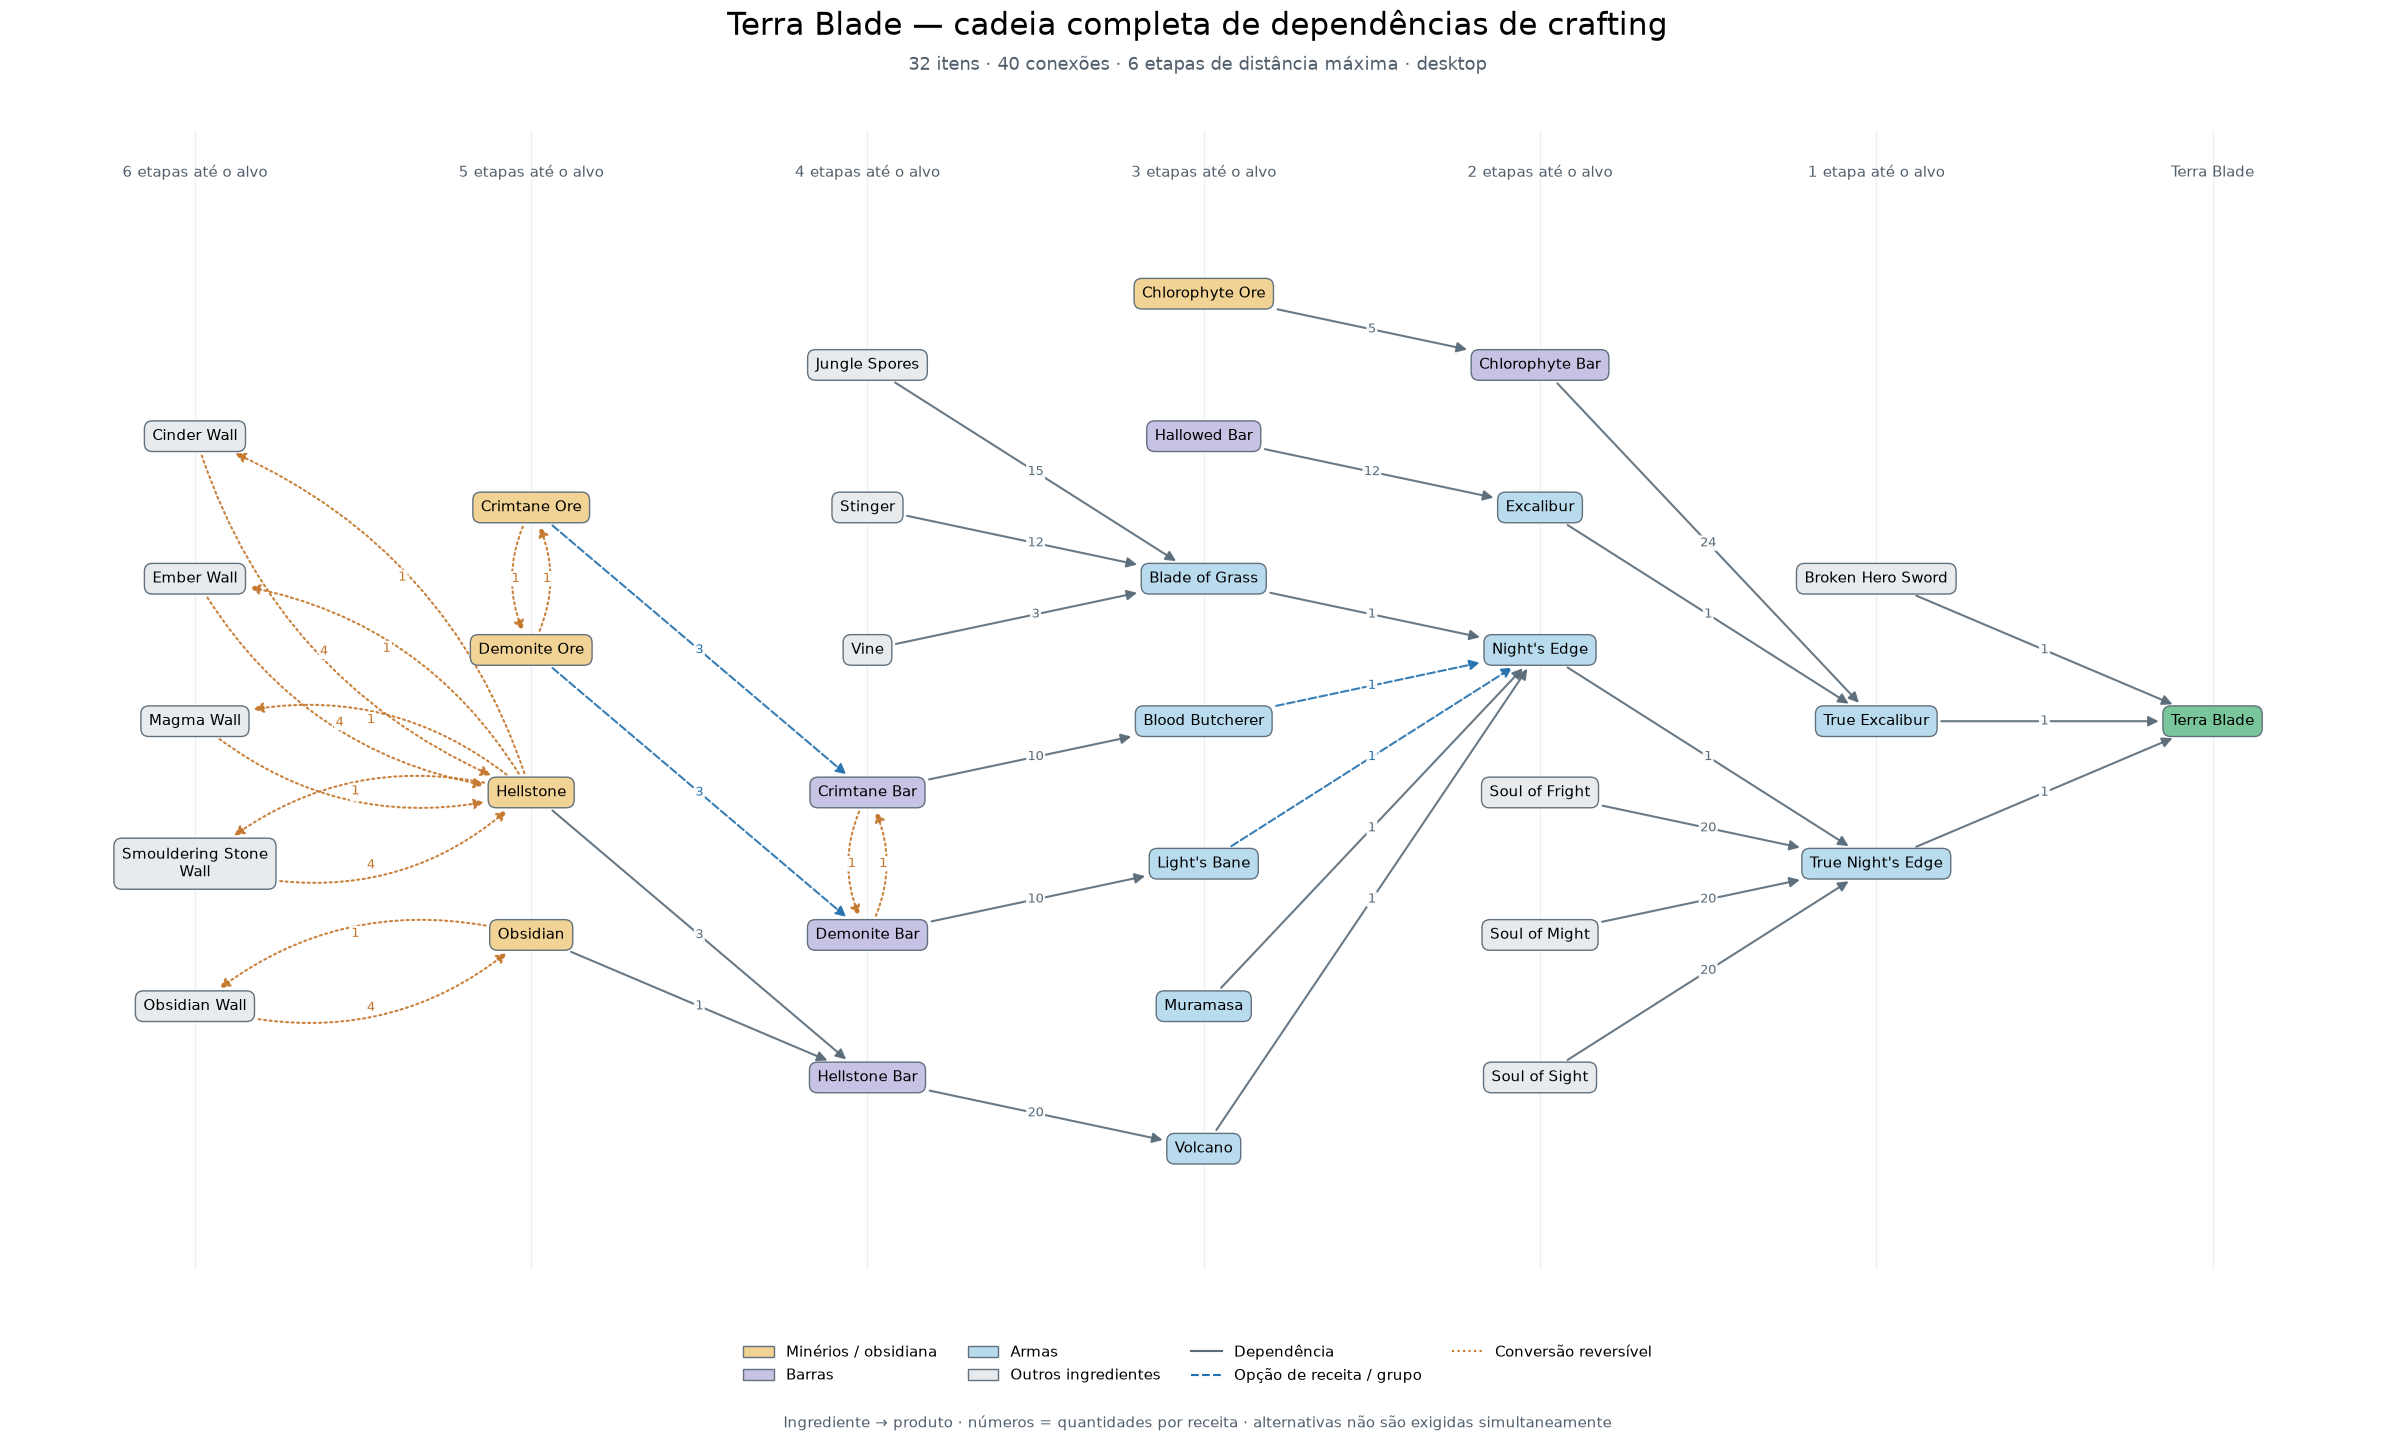

,produto,ingredientes (todos os slots),quantidade produzida,estações/condições,índice da receita
0,Ember Wall,1 × (Hellstone),4,"Work Bench, Ecto Mist",2167
1,Cinder Wall,1 × (Hellstone),4,"Work Bench, Ecto Mist",2169
2,Magma Wall,1 × (Hellstone),4,"Work Bench, Ecto Mist",2171
3,Smouldering Stone Wall,1 × (Hellstone),4,"Work Bench, Ecto Mist",2173
4,Obsidian Wall,1 × (Obsidian),4,"Work Bench, Ecto Mist",2177
5,Crimtane Ore,1 × (Demonite Ore),1,Chlorophyte Extractinator,189
6,Demonite Ore,1 × (Crimtane Ore),1,Chlorophyte Extractinator,190
7,Hellstone,4 × (Ember Wall),1,Work Bench,2168
8,Hellstone,4 × (Cinder Wall),1,Work Bench,2170
9,Hellstone,4 × (Magma Wall),1,Work Bench,2172


Visualização validada: 32 itens, 40 conexões e 28 receitas completas.
Todos os ancestrais foram incluídos; caminhos dos minérios até a Terra Blade verificados.


In [9]:
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, Patch

target = "TerraBlade"
# A busca reversa visita cada item uma vez, mesmo quando há ciclos.
levels = dict(nx.single_source_shortest_path_length(G.reverse(copy=False), target))
crafting_chain = G.subgraph(levels).copy()
max_depth = max(levels.values())
chain_recipe_ids = {
    recipe_id for recipe_id, recipe in recipes_desktop.items()
    if recipe["result"] in crafting_chain
}

assert set(crafting_chain) == nx.ancestors(G, target) | {target}
assert set(crafting_chain.edges) == {(u, v) for u, v in G.edges if u in levels and v in levels}
assert all(nx.has_path(crafting_chain, key, target) for key in crafting_chain)
assert all(set(G.predecessors(key)) <= set(crafting_chain) for key in crafting_chain)
for ore in ("DemoniteOre", "CrimtaneOre", "ChlorophyteOre", "Hellstone", "Obsidian"):
    assert ore in crafting_chain, f"Material ausente da visualização: {ore}"
    assert nx.has_path(crafting_chain, ore, target)
for recipe_id in chain_recipe_ids:
    assert all(key in crafting_chain for ingredient in recipes_desktop[recipe_id]["resolved_ingredients"]
               for key in ingredient["options"])

# Ordenar por ramo reduz cruzamentos entre as colunas, mantendo posições determinísticas.
branch_order = {}
for depth in range(max_depth + 1):
    for key in sorted(k for k in crafting_chain if levels[k] == depth):
        if depth == 0:
            branch_order[key] = ()
        else:
            parents = [p for p in crafting_chain.successors(key) if levels[p] == depth - 1]
            parent = min(parents, key=lambda p: branch_order[p])
            branch_order[key] = branch_order[parent] + (G.nodes[key]["name"],)

layers = {}
positions = {}
for depth in range(max_depth + 1):
    layer = sorted((key for key in crafting_chain if levels[key] == depth),
                   key=lambda key: branch_order[key])
    layers[depth] = layer
    for index, key in enumerate(layer):
        positions[key] = (max_depth - depth, (len(layer) - 1) / 2 - index)

recipe_ids_by_product = defaultdict(set)
for recipe_id in chain_recipe_ids:
    recipe_ids_by_product[recipes_desktop[recipe_id]["result"]].add(recipe_id)

edge_kinds = {}
edge_labels = {}
for ingredient, product, attributes in crafting_chain.edges(data=True):
    uses = [u for u in attributes["uses"] if u["recipe_id"] in chain_recipe_ids]
    edge_labels[(ingredient, product)] = "/".join(str(amount) for amount in sorted({u["amount"] for u in uses}))
    if crafting_chain.has_edge(product, ingredient):
        edge_kinds[(ingredient, product)] = "reversible"
    elif (all(u["group"] is not None for u in uses)
          or {u["recipe_id"] for u in uses} != recipe_ids_by_product[product]):
        edge_kinds[(ingredient, product)] = "alternative"
    else:
        edge_kinds[(ingredient, product)] = "regular"

# Categorias da legenda derivadas dos metadados originais.
node_colors = {}
for key in crafting_chain:
    item = G.nodes[key]
    if key == target:
        node_colors[key] = "#7ac69c"
    elif "ore" in item.get("subcategories", []) or key in {"Hellstone", "Obsidian"}:
        node_colors[key] = "#f1d395"
    elif "bar" in item.get("subcategories", []):
        node_colors[key] = "#c6c3e5"
    elif "weapon" in item.get("categories", []):
        node_colors[key] = "#b9dbee"
    else:
        node_colors[key] = "#e7ebed"

fig, ax = plt.subplots(figsize=(25, 15))
fig.subplots_adjust(left=0.025, right=0.98, top=0.89, bottom=0.13)
ax.set_xlim(-0.55, max_depth + 0.55)
max_rows = max(map(len, layers.values()))
ax.set_ylim(-max_rows / 2 - 0.35, max_rows / 2 + 0.65)
for depth, layer in layers.items():
    x = max_depth - depth
    ax.axvline(x, color="#edf0f2", linewidth=1, zorder=0)
    title = "Terra Blade" if depth == 0 else f"{depth} etapa{'s' if depth > 1 else ''} até o alvo"
    ax.text(x, max_rows / 2 + 0.35, title, ha="center", va="center", fontsize=11, color="#52606d")

# Caixas ajustadas aos nomes evitam que rótulos longos ultrapassem os vértices.
node_texts = {}
for key, (x, y) in positions.items():
    node_texts[key] = ax.text(
        x, y, fill(G.nodes[key]["name"], width=17), ha="center", va="center",
        fontsize=10.5, zorder=4,
        bbox=dict(boxstyle="round,pad=0.55", facecolor=node_colors[key],
                  edgecolor="#62717d", linewidth=1),
    )
fig.canvas.draw()
renderer = fig.canvas.get_renderer()


def box_boundary(center, direction, key):
    """Interseção da direção da seta com a borda da caixa, em pixels."""
    box = node_texts[key].get_bbox_patch().get_window_extent(renderer)
    half_sizes = (box.width / 2, box.height / 2)
    scale = min(half / abs(delta) for half, delta in zip(half_sizes, direction) if delta != 0)
    return center + scale * direction


styles = {
    "regular": ("#596b79", "solid"),
    "alternative": ("#2371ae", "dashed"),
    "reversible": ("#c47529", "dotted"),
}
for (source, destination), kind in edge_kinds.items():
    color, linestyle = styles[kind]
    start, end = positions[source], positions[destination]
    curvature = 0.22 if kind == "reversible" else 0.0
    p1, p2 = ax.transData.transform([start, end])
    dx, dy = p2 - p1
    control = (p1 + p2) / 2
    control[0] += curvature * dy
    control[1] -= curvature * dx
    start_boundary = box_boundary(p1, control - p1, source)
    end_boundary = box_boundary(p2, control - p2, destination)
    clipped_start, clipped_end = ax.transData.inverted().transform([start_boundary, end_boundary])
    arrow = FancyArrowPatch(
        clipped_start, clipped_end,
        arrowstyle="-|>", mutation_scale=15, shrinkA=3, shrinkB=3,
        connectionstyle=f"arc3,rad={curvature}", linewidth=1.5,
        color=color, linestyle=linestyle, alpha=0.9, zorder=1,
    )
    ax.add_patch(arrow)
    # Meio da curva em coordenadas de tela, para separar rótulos de setas opostas.
    midpoint = (p1 + p2) / 2
    midpoint[0] += curvature * dy / 2
    midpoint[1] -= curvature * dx / 2
    label_x, label_y = ax.transData.inverted().transform(midpoint)
    ax.text(label_x, label_y, edge_labels[(source, destination)],
            ha="center", va="center", fontsize=9, color=color, zorder=3,
            bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none", alpha=0.92))

fig.suptitle("Terra Blade — cadeia completa de dependências de crafting", fontsize=22, y=0.97)
fig.text(0.5, 0.93,
         f"{crafting_chain.number_of_nodes()} itens · {crafting_chain.number_of_edges()} conexões · "
         f"{max_depth} etapas de distância máxima · desktop",
         ha="center", fontsize=13, color="#52606d")
legend = [
    Patch(facecolor="#f1d395", edgecolor="#62717d", label="Minérios / obsidiana"),
    Patch(facecolor="#c6c3e5", edgecolor="#62717d", label="Barras"),
    Patch(facecolor="#b9dbee", edgecolor="#62717d", label="Armas"),
    Patch(facecolor="#e7ebed", edgecolor="#62717d", label="Outros ingredientes"),
    Line2D([0], [0], color=styles["regular"][0], label="Dependência"),
    Line2D([0], [0], color=styles["alternative"][0], linestyle="--", label="Opção de receita / grupo"),
    Line2D([0], [0], color=styles["reversible"][0], linestyle=":", label="Conversão reversível"),
]
fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(0.5, 0.045), ncol=4, frameon=False, fontsize=11)
fig.text(0.5, 0.025, "Ingrediente → produto · números = quantidades por receita · alternativas não são exigidas simultaneamente",
         ha="center", fontsize=11, color="#52606d")
ax.set_axis_off()
plt.show()

chain_stations = []
for recipe_id in sorted(chain_recipe_ids, key=lambda rid: (-levels[recipes_desktop[rid]["result"]], rid)):
    recipe = recipes_desktop[recipe_id]
    ingredient_descriptions = []
    for ingredient in recipe["resolved_ingredients"]:
        names = " OU ".join(items_by_key[key]["name"] for key in ingredient["options"])
        ingredient_descriptions.append(f"{ingredient['amount']} × ({names})")
    chain_stations.append({
        "produto": G.nodes[recipe["result"]]["name"],
        "ingredientes (todos os slots)": " + ".join(ingredient_descriptions),
        "quantidade produzida": recipe["amount"],
        "estações/condições": ", ".join(recipe["stations"]),
        "índice da receita": recipe_id,
    })
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(pd.DataFrame(chain_stations))
print(f"Visualização validada: {crafting_chain.number_of_nodes()} itens, "
      f"{crafting_chain.number_of_edges()} conexões e {len(chain_recipe_ids)} receitas completas.")
print("Todos os ancestrais foram incluídos; caminhos dos minérios até a Terra Blade verificados.")

## Resultado desta etapa

`G`, `recipes_desktop`, `items_by_key`, `recipe_groups`, `station_catalog` e
`milestones_by_id` ficam disponíveis na memória do notebook. Nenhum JSON original foi alterado
ou substituído. Os números e exemplos acima são resultados da execução, não valores simulados.
O grafo representa dependências possíveis; para recuperar uma receita executável, consulte
`recipes_desktop[recipe_id]`, incluindo seus grupos, quantidades e estações.